In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import h5py
import torch

%matplotlib inline
plt.rcParams["figure.dpi"] = 300.0


In [3]:
# --- Load pretrained HyPER components ---
# HyPER ("Hybrid PDE Predictor with Reinforcement Learning") pairs a neural
# surrogate with a physics simulator, using an RL actor to decide, at each
# rollout step, whether to trust the fast surrogate or call the expensive
# simulator to correct the state. Here we load the three pretrained pieces.
import sys
if ".." not in sys.path:
    sys.path.insert(0, "..")  # make src/ importable (utils, models, data)

import utils
from models.twod_unet_cond import Unet as UnetCond
from models.resnet import resnet18_cond

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ckpt_dir = "../../model_checkpoints"

# Neural surrogates: 2D conditional U-Nets (time-conditioned, 1 channel smoke
# field). Two variants differ only in training-set size:
#   unet-400 -> trained on 400 trajectories (small dataset)
#   unet-800 -> trained on 800 trajectories (large dataset)
def build_surrogate():
    return UnetCond(1, 0, 1, 0, 1, 1, 64, "gelu",
                    ch_mults=[1, 2, 2], is_attn=[False, False, False])

surrogate_400 = utils.load_model(
    f"{ckpt_dir}/unet-400-lr-0.0001-bs-8-epochs-200-1_model_checkpoint_199_final.pt",
    build_surrogate()).to(device).eval()
surrogate_800 = utils.load_model(
    f"{ckpt_dir}/unet-800-lr-0.0001-bs-8-epochs-200-1_model_checkpoint_199_final.pt",
    build_surrogate()).to(device).eval()

# RL actor / decision model: ResNet-18 that outputs S=4 Bernoulli logits per
# call (one surrogate-vs-simulator decision per step over a 4-step window).
# Trained with REINFORCE at lambda=0.3 (target ~30% simulator usage).
actor = resnet18_cond(num_classes=4, param_conditioning=False)
actor = utils.load_model(
    f"{ckpt_dir}/actor-0.3-reinforce-eta-0.0-lr-1e-05_model_checkpoint_29.pt",
    actor).to(device).eval()

print(f"Loaded on {device}:")
print(f"  surrogate_400: {sum(p.numel() for p in surrogate_400.parameters()):,} params")
print(f"  surrogate_800: {sum(p.numel() for p in surrogate_800.parameters()):,} params")
print(f"  actor        : {sum(p.numel() for p in actor.parameters()):,} params")

Loaded on cuda:
  surrogate_400: 12,295,233 params
  surrogate_800: 12,295,233 params
  actor        : 11,751,300 params


In [4]:
# --- Load the Navier-Stokes dataset ---
# 1000 smoke-plume trajectories on a 64x64 grid, 64 timesteps each. We reproduce
# the paper's split exactly: a 40/40/10/10 split (train / RL / val / test) with
# a fixed seed, then evaluate HyPER on the held-out TEST trajectories. We request
# velocity fields too, since the phiflow simulator needs them for its corrections.
from torch.utils.data import DataLoader, random_split
from data.navier_stokes_dataset import NavierStokesDataset

dataset_path = "../../data/ns_data_64_1000.h5"
dataset_split = (0.40, 0.40, 0.10, 0.10)  # train, RL, val, test
random_seed = 42

# Rollout window: predict timesteps ST..FT-1 autoregressively from the state at ST-1.
ST, FT = 8, 28

# Dataset statistics used to standardize the smoke field (from training).
smoke_mean = 0.7322910149367649
smoke_std = 0.43668617344401106

dataset = NavierStokesDataset(dataset_path, provide_velocity=True)
train_dataset, rl_dataset, val_dataset, test_dataset = random_split(
    dataset, dataset_split, generator=torch.Generator().manual_seed(random_seed))

# batch_size=1: the HyPER rollout (and phiflow simulator) operate one trajectory at a time.
test_dataloader = DataLoader(test_dataset, batch_size=1, shuffle=False, pin_memory=True)

print(f"Total trajectories : {len(dataset)}")
print(f"  train / rl / val / test = "
      f"{len(train_dataset)} / {len(rl_dataset)} / {len(val_dataset)} / {len(test_dataset)}")

_sample = test_dataset[0]
print(f"Per-trajectory fields (time, H, W):")
for k in ("smoke", "velocity_x", "velocity_y"):
    print(f"  {k:12s}: {tuple(_sample[k].shape)}")
print(f"Rollout window: predict t={ST}..{FT - 1} from state at t={ST - 1}")

Total trajectories : 1000
  train / rl / val / test = 400 / 400 / 100 / 100
Per-trajectory fields (time, H, W):
  smoke       : (64, 64, 64)
  velocity_x  : (64, 64, 64)
  velocity_y  : (64, 64, 64)
Rollout window: predict t=8..27 from state at t=7


In [5]:
# --- The phiflow physics simulator (HyPER's correction step) ---
# When the RL actor chooses to CORRECT a step, HyPER advances the state with a
# real fluid solver instead of the surrogate. We use phiflow to run one step of
# the incompressible Navier-Stokes solver: advect smoke -> apply buoyancy ->
# advect + diffuse velocity -> project to divergence-free. The torch<->phiflow
# converters below move the smoke (centered grid) and velocity (staggered grid)
# fields between the two representations. Ported verbatim from the paper's
# train_rl_reinforce_ns.py / test_all_models_ns.py so the physics matches exactly.
from phi.torch.flow import (Box, CenteredGrid, StaggeredGrid, Solve, advect, diffuse,
                            extrapolation, fluid, spatial, channel)
from phi.math import tensor as phi_tensor
from phiml.math import Diverged, NotConverged

# Simulator parameters (from the RL training config).
dt = 96.0 / 64.0          # timestep duration (seconds)
buoyancy_factor = 0.5     # upward buoyancy applied to the smoke field
diffusion_coef = 0.01     # velocity diffusion coefficient


def torch_to_phi_centered(data):
    # smoke: (H, W) torch -> phiflow CenteredGrid on a 32x32 domain
    phi_ten = phi_tensor(data.transpose(1, 0), spatial('x,y'))  # transpose so x,y land in the right dims
    phi_grid = CenteredGrid(phi_ten, extrapolation.BOUNDARY, Box['x,y', 0:32.0, 0:32.0])
    return phi_grid


def phi_centered_to_torch(data):
    data_np = data.values.numpy('x,y')
    return torch.from_numpy(data_np.transpose(1, 0))  # back to (y, x) order


def torch_to_phi_staggered(data_x, data_y):
    # velocity components: (H, W) torch -> phiflow StaggeredGrid.
    # Staggered grids store one extra sample per dim, so we pad by replicating the edge.
    data_x = torch.cat((data_x, data_x[:, -1].reshape(data_x.shape[1], -1)), 1)
    data_x = torch.cat((data_x, data_x[-1, :].reshape(-1, data_x.shape[1])), 0)
    data_y = torch.cat((data_y, data_y[:, -1].reshape(data_y.shape[1], -1)), 1)
    data_y = torch.cat((data_y, data_y[-1, :].reshape(-1, data_y.shape[1])), 0)
    stacked = torch.stack((data_x.transpose(1, 0), data_y.transpose(1, 0)), dim=2)
    stacked_ten = phi_tensor(stacked, spatial('x,y'), channel('vector'))
    phi_grid = StaggeredGrid(stacked_ten, extrapolation.ZERO, Box['x,y', 0:32.0, 0:32.0])
    return phi_grid


def phi_staggered_to_torch(data):
    field = data.staggered_tensor().numpy('x,y,vector')
    field_x = torch.from_numpy(field[:-1, :-1, 0].transpose(1, 0))  # drop the extra staggered row/col
    field_y = torch.from_numpy(field[:-1, :-1, 1].transpose(1, 0))
    return field_x, field_y


def call_sim(smoke_grid, velocity_grid, dt, buoyancy_factor, diffusion_coef):
    # One incompressible Navier-Stokes step. (The paper wraps this in phiflow's
    # @jit_compile to speed up training over many trajectories; for a tutorial
    # running a handful of rollouts we keep it eager -- more robust and reproducible,
    # and the numerical result is identical.)
    smoke_grid = advect.semi_lagrangian(smoke_grid, velocity_grid, dt)               # transport smoke
    buoyancy_force = (smoke_grid * (0, buoyancy_factor)).at(velocity_grid)            # smoke -> upward force
    velocity_grid = advect.semi_lagrangian(velocity_grid, velocity_grid, dt) + dt * buoyancy_force
    velocity_grid = diffuse.explicit(velocity_grid, diffusion_coef, dt)              # viscosity
    # Pressure projection: subtract grad(p) so the velocity is divergence-free.
    # With closed boundaries the pressure Poisson system is singular -- pressure is
    # only defined up to an additive constant -- so the residual floors around 1e-3
    # and can never reach the solver's default 1e-5 check. phiflow's direct solver
    # (method "auto") still returns the correct projection (it drives mean|div| from
    # ~0.3 down to ~5e-6); we just `suppress` the unreachable-tolerance exception so
    # that physically-good solution is accepted instead of raising.
    velocity_grid, _ = fluid.make_incompressible(
        velocity_grid,
        solve=Solve("auto", rel_tol=1e-5, abs_tol=1e-5, max_iterations=10000,
                    suppress=[Diverged, NotConverged]))
    return smoke_grid, velocity_grid


print("phiflow simulator ready.")
print(f"  dt={dt:.3f}s  buoyancy_factor={buoyancy_factor}  diffusion_coef={diffusion_coef}")

phiflow simulator ready.
  dt=1.500s  buoyancy_factor=0.5  diffusion_coef=0.01


In [6]:
# --- The HyPER rollout ---
# Autoregressively predict smoke from t=ST..FT-1. The rollout proceeds in windows
# of S=4 steps. At the start of each window the actor looks at (current_pred,
# initial_state) + a time embedding and emits S Bernoulli probabilities; we sample
# one action per step:
#     action = 0  -> advance with the fast neural SURROGATE
#     action = 1  -> advance with the phiflow SIMULATOR (the correction)
# The chosen output becomes the input to the next step (autoregressive feedback).
# Faithful port of the HyPER branch in test_all_models_ns.py.
from torch.distributions import Bernoulli

S = 4  # actor decision-window length (matches the trained actor's num_classes)


def hyper_rollout(batch, actor, surrogate, S=S, ST=ST, FT=FT, greedy=False):
    """Run one HyPER rollout over a single test trajectory.

    batch: dict from test_dataloader (B=1) with smoke / velocity_x / velocity_y, each (B, T, H, W).
    greedy: if True, pick action = (prob > 0.5) deterministically; if False, sample (paper default).
    Returns per-step predictions, ground truth, the simulator-usage mask, actions, and MSEs.
    """
    T = FT - ST
    smoke = batch["smoke"].unsqueeze(2).to(device)        # B, T, 1, H, W
    velocity_x = batch["velocity_x"].unsqueeze(2).to(device)
    velocity_y = batch["velocity_y"].unsqueeze(2).to(device)
    H, W = smoke.shape[3], smoke.shape[4]

    smoke_norm = (smoke - smoke_mean) / smoke_std
    # Seed the rollout with the (normalized) true state at t = ST-1.
    last_pred = smoke_norm[:, ST - 1, :, :, :].unsqueeze(1)   # B, 1, 1, H, W
    init_state = smoke_norm[:, ST - 1, :, :, :].unsqueeze(1)

    preds = torch.zeros((T, H, W))
    gts = torch.zeros((T, H, W))
    sim_mask = torch.zeros(T, dtype=torch.bool)   # True where the simulator was used
    mses = torch.zeros(T)                         # per-step MSE (original scale)
    actions = []
    num_sim_calls = num_model_calls = 0

    start_time = ST
    for _ in range(T // S):
        while last_pred.dim() < 5:
            last_pred = last_pred.unsqueeze(0)
        # Actor decision for this window: input is (current_pred, initial_state) stacked on channels.
        rl_input = torch.cat((last_pred.squeeze(1), init_state.squeeze(1)), dim=1)   # B, 2, H, W
        time_tensor = torch.full((rl_input.shape[0],), start_time - 1, device=device)
        rl_probs = torch.sigmoid(actor(rl_input, time_tensor)).squeeze()
        if greedy:
            rl_action = (rl_probs > 0.5).float()
        else:
            rl_action = Bernoulli(probs=rl_probs).sample()
        actions.append(rl_action.tolist())

        for t in range(start_time, start_time + S):
            if rl_action[t - start_time] == 0:
                # --- Surrogate step ---
                num_model_calls += 1
                model_inputs = last_pred
                while model_inputs.dim() < 5:
                    model_inputs = model_inputs.unsqueeze(0)
                unet_time = torch.full((model_inputs.shape[0],), t, device=device)
                output = surrogate(model_inputs, unet_time)
                last_pred = output.detach()
                used_sim = False
            else:
                # --- Simulator step (correction) using ground-truth velocity at t-1 ---
                num_sim_calls += 1
                last_pred_unnorm = (last_pred.detach() * smoke_std + smoke_mean).clone()
                smoke_grid = torch_to_phi_centered(last_pred_unnorm.squeeze())
                velocity_grid = torch_to_phi_staggered(
                    velocity_x[:, t - 1].squeeze(), velocity_y[:, t - 1].squeeze())
                smoke_grid, velocity_grid = call_sim(
                    smoke_grid, velocity_grid, dt, buoyancy_factor, diffusion_coef)
                sim_output_smoke = phi_centered_to_torch(smoke_grid).to(device)
                sim_output_smoke = (sim_output_smoke - smoke_mean) / smoke_std
                last_pred = sim_output_smoke.detach()
                used_sim = True

            # Record ground truth + prediction (back in original, unnormalized scale).
            k = t - ST
            gts[k] = smoke[:, t, :, :, :].squeeze()
            pred_unnorm = (last_pred * smoke_std + smoke_mean).squeeze()
            preds[k] = pred_unnorm
            mses[k] = torch.mean((pred_unnorm - gts[k].to(device)) ** 2).item()
            sim_mask[k] = used_sim
        start_time += S

    return {
        "preds": preds, "gts": gts, "sim_mask": sim_mask, "mses": mses,
        "actions": actions, "num_sim_calls": num_sim_calls, "num_model_calls": num_model_calls,
        "percent_sim": num_sim_calls / T,
    }


print("hyper_rollout defined. Rollout window:",
      f"t={ST}..{FT - 1} ({FT - ST} steps) in {(FT - ST) // S} windows of S={S}.")

hyper_rollout defined. Rollout window: t=8..27 (20 steps) in 5 windows of S=4.


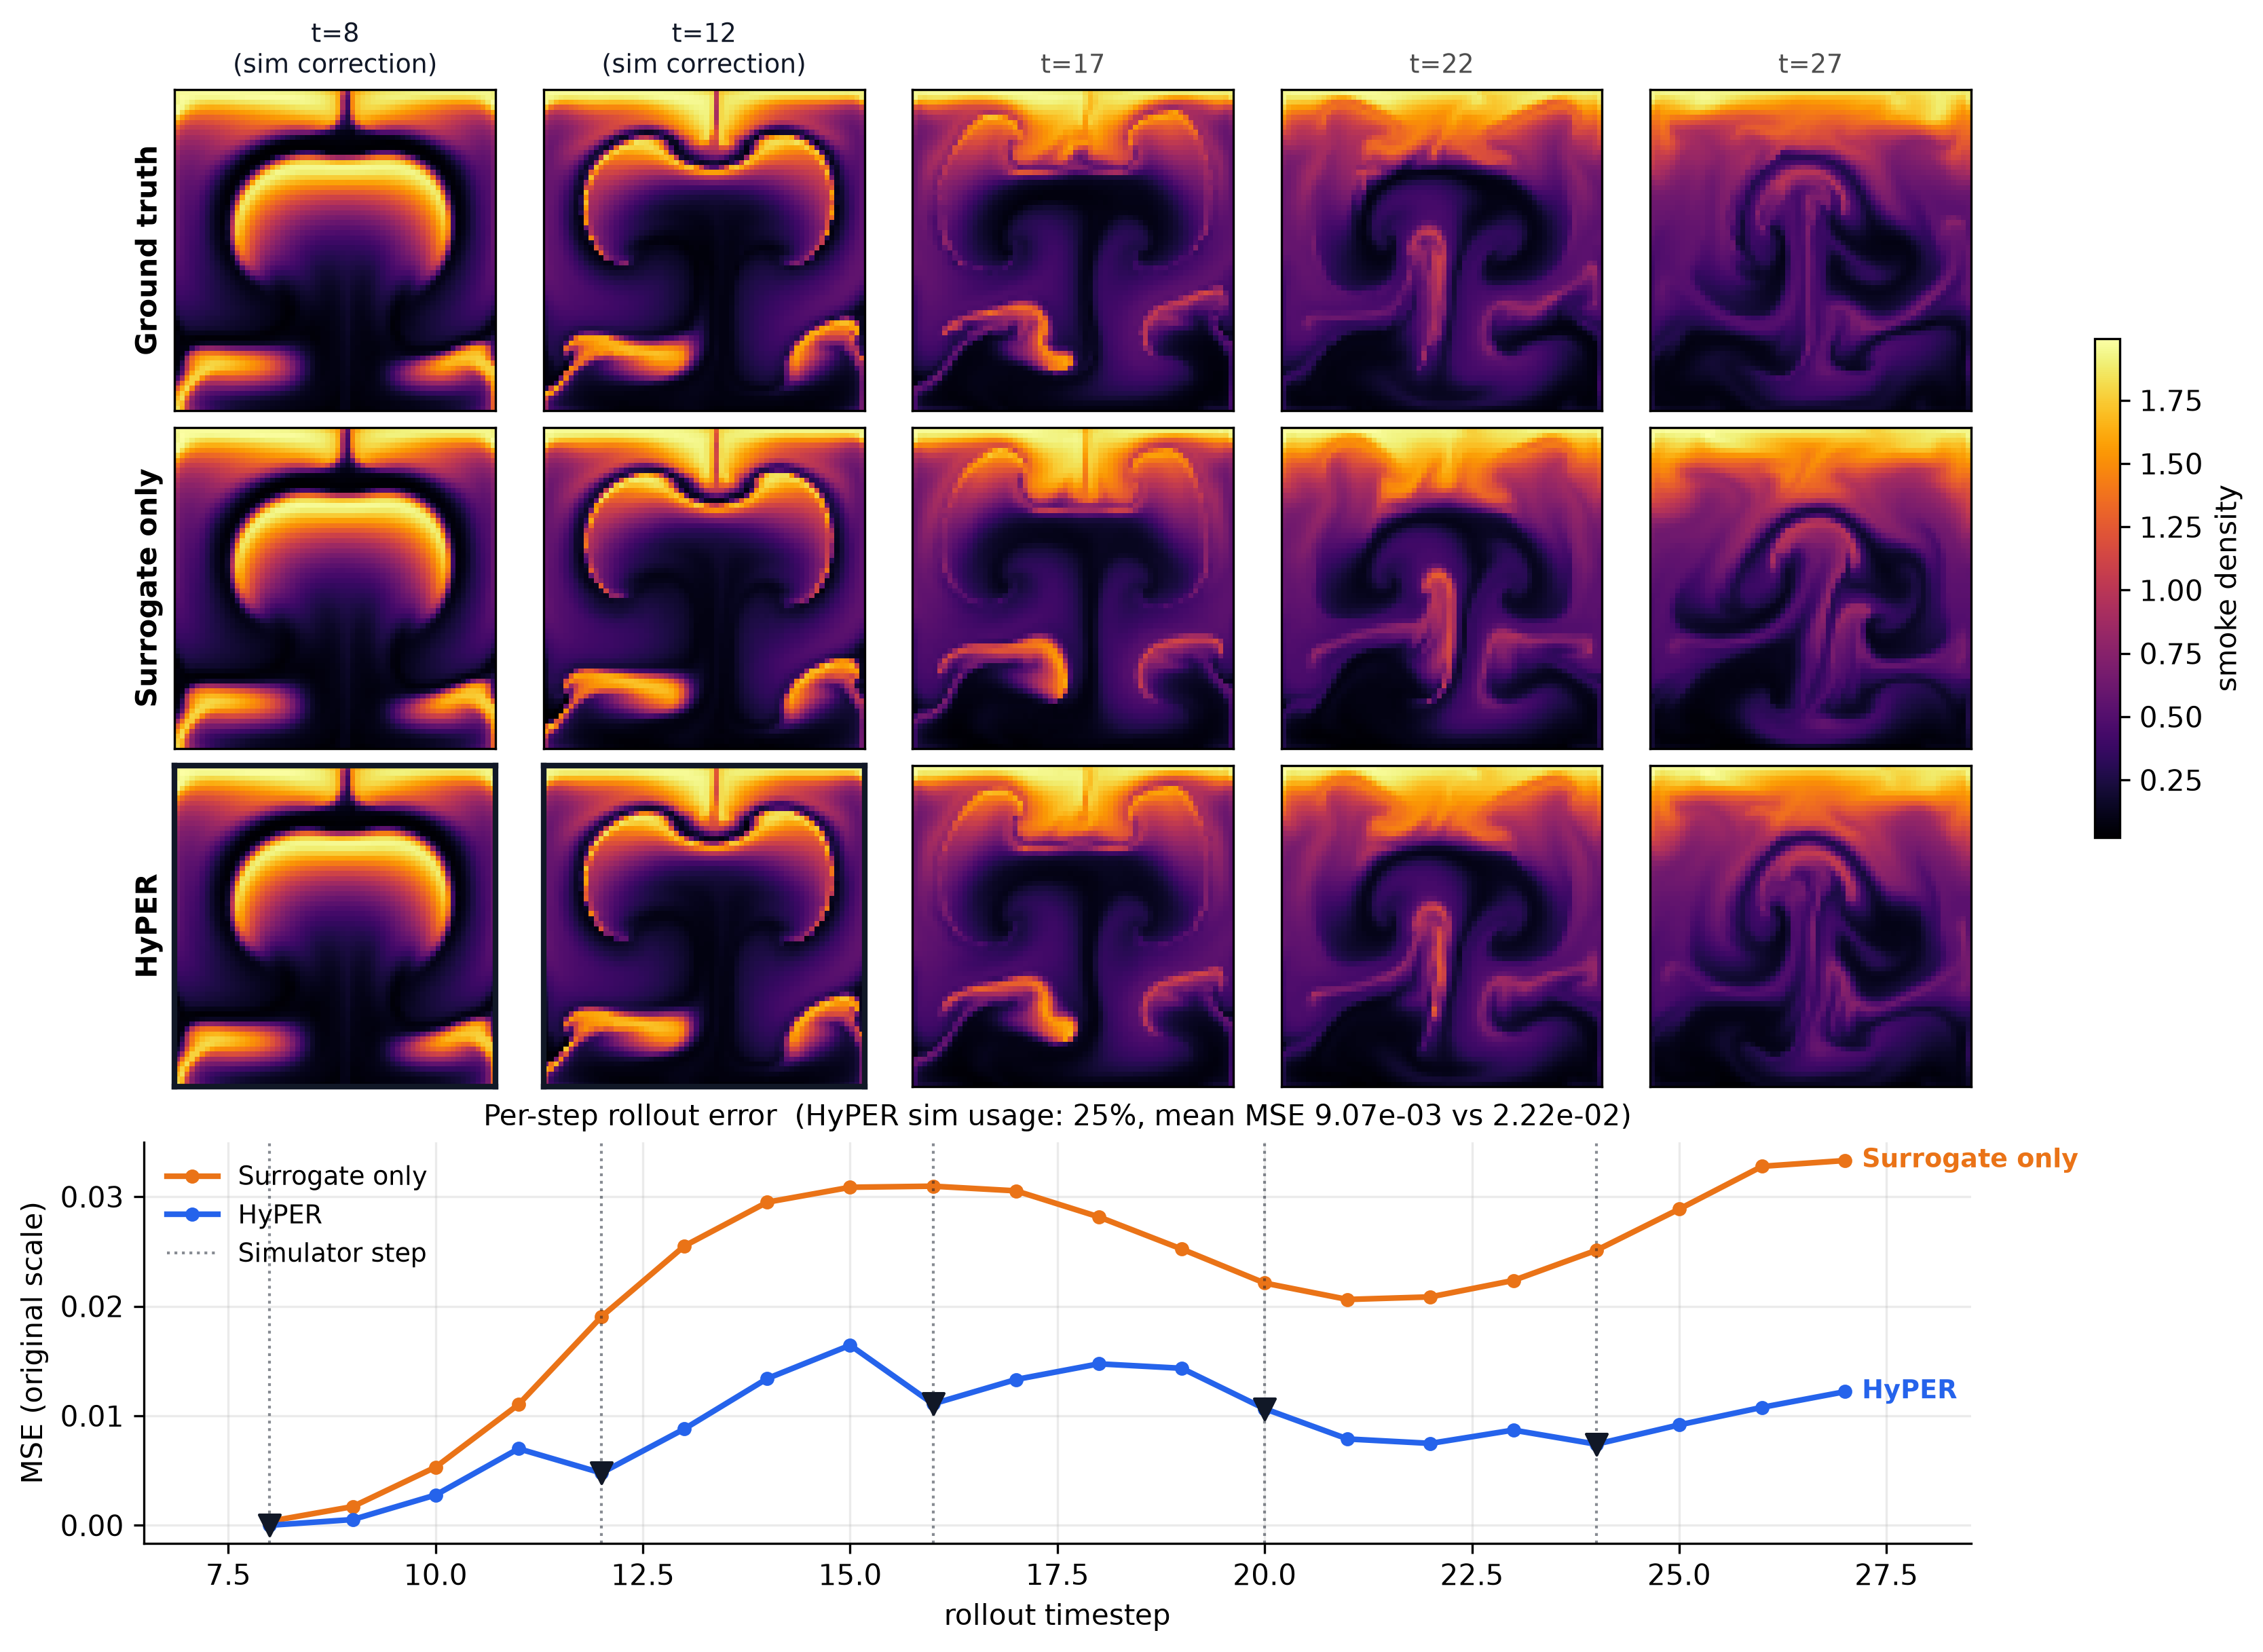

HyPER reduces mean rollout MSE by 59.2% on this trajectory.


In [7]:
# --- Visualize: HyPER vs surrogate-only rollout, with simulator steps marked ---
# Top block: smoke fields at a few rollout timesteps -- ground truth vs surrogate-only
# vs HyPER. Bottom: per-step MSE over the whole rollout for both methods, with the
# steps where HyPER invoked the physics simulator marked. We use the weaker 400-traj
# surrogate so the benefit of correction is clearest (the paper's motivating case).
import warnings
import matplotlib.gridspec as gridspec
warnings.filterwarnings("ignore")  # silence phiflow/pytorch beta warnings
torch.manual_seed(0)

# Two-series categorical colors (fixed order; CVD-distinct), + sequential cmap for fields.
C_HYPER, C_SURR, C_SIM = "#2563eb", "#ea7317", "#111827"  # blue, orange, near-black marks
FIELD_CMAP = "inferno"

viz_batch = next(iter(test_dataloader))

class _ZeroActor:  # forces every action to 0 -> pure surrogate rollout (no corrections)
    def __call__(self, x, t):
        return torch.full((x.shape[0], S), -1e9, device=x.device)

hyper = hyper_rollout(viz_batch, actor, surrogate_400, greedy=True)
surr_only = hyper_rollout(viz_batch, _ZeroActor(), surrogate_400, greedy=True)

T = FT - ST
steps = np.arange(ST, FT)                    # absolute timesteps for the x-axis
sim_steps = np.where(hyper["sim_mask"].numpy())[0]   # rollout indices where sim was used

# Choose 5 snapshot columns spread across the rollout.
col_idx = np.linspace(0, T - 1, 5, dtype=int)
vmin = float(hyper["gts"].min())
vmax = float(hyper["gts"].max())

fig = plt.figure(figsize=(11, 8), constrained_layout=True)
gs = gridspec.GridSpec(4, len(col_idx), figure=fig, height_ratios=[1, 1, 1, 1.25])

rows = [("Ground truth", hyper["gts"]),
        ("Surrogate only", surr_only["preds"]),
        ("HyPER", hyper["preds"])]
im = None
for r, (label, data) in enumerate(rows):
    for c, k in enumerate(col_idx):
        ax = fig.add_subplot(gs[r, c])
        im = ax.imshow(data[k].numpy(), cmap=FIELD_CMAP, vmin=vmin, vmax=vmax, origin="lower")
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            used_sim = k in sim_steps
            ax.set_title(f"t={ST + k}" + ("\n(sim correction)" if used_sim else ""),
                         fontsize=9, color=C_SIM if used_sim else "0.3")
        if c == 0:
            ax.set_ylabel(label, fontsize=10, fontweight="bold")
        # Outline HyPER panels that came from a simulator correction.
        if r == 2 and k in sim_steps:
            for sp in ax.spines.values():
                sp.set(visible=True, color=C_SIM, linewidth=2)
fig.colorbar(im, ax=fig.axes, shrink=0.5, location="right", pad=0.01, label="smoke density")

# Bottom: per-step MSE over the full rollout.
axm = fig.add_subplot(gs[3, :])
axm.plot(steps, surr_only["mses"].numpy(), color=C_SURR, lw=2, marker="o", ms=4, label="Surrogate only")
axm.plot(steps, hyper["mses"].numpy(), color=C_HYPER, lw=2, marker="o", ms=4, label="HyPER")
# Mark simulator-correction steps.
for j, st in enumerate(sim_steps):
    axm.axvline(ST + st, color=C_SIM, ls=":", lw=1, alpha=0.5,
                label="Simulator step" if j == 0 else None)
axm.scatter(steps[sim_steps], hyper["mses"].numpy()[sim_steps],
            color=C_SIM, zorder=5, s=55, marker="v", label=None)
# Direct labels (identity not by color alone).
axm.annotate("Surrogate only", (steps[-1], surr_only["mses"][-1].item()),
             color=C_SURR, fontsize=9, fontweight="bold", va="center", xytext=(6, 0),
             textcoords="offset points")
axm.annotate("HyPER", (steps[-1], hyper["mses"][-1].item()),
             color=C_HYPER, fontsize=9, fontweight="bold", va="center", xytext=(6, 0),
             textcoords="offset points")
axm.set_xlabel("rollout timestep"); axm.set_ylabel("MSE (original scale)")
axm.set_title(f"Per-step rollout error  "
              f"(HyPER sim usage: {hyper['percent_sim']*100:.0f}%, "
              f"mean MSE {hyper['mses'].mean():.2e} vs {surr_only['mses'].mean():.2e})",
              fontsize=10)
axm.legend(loc="upper left", frameon=False, fontsize=9)
axm.grid(True, alpha=0.25); axm.margins(x=0.08)
for sp in ("top", "right"):
    axm.spines[sp].set_visible(False)

plt.show()
print(f"HyPER reduces mean rollout MSE by "
      f"{(1 - hyper['mses'].mean() / surr_only['mses'].mean()) * 100:.1f}% on this trajectory.")

Rollouts: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 25/25 [00:36<00:00,  1.46s/traj]


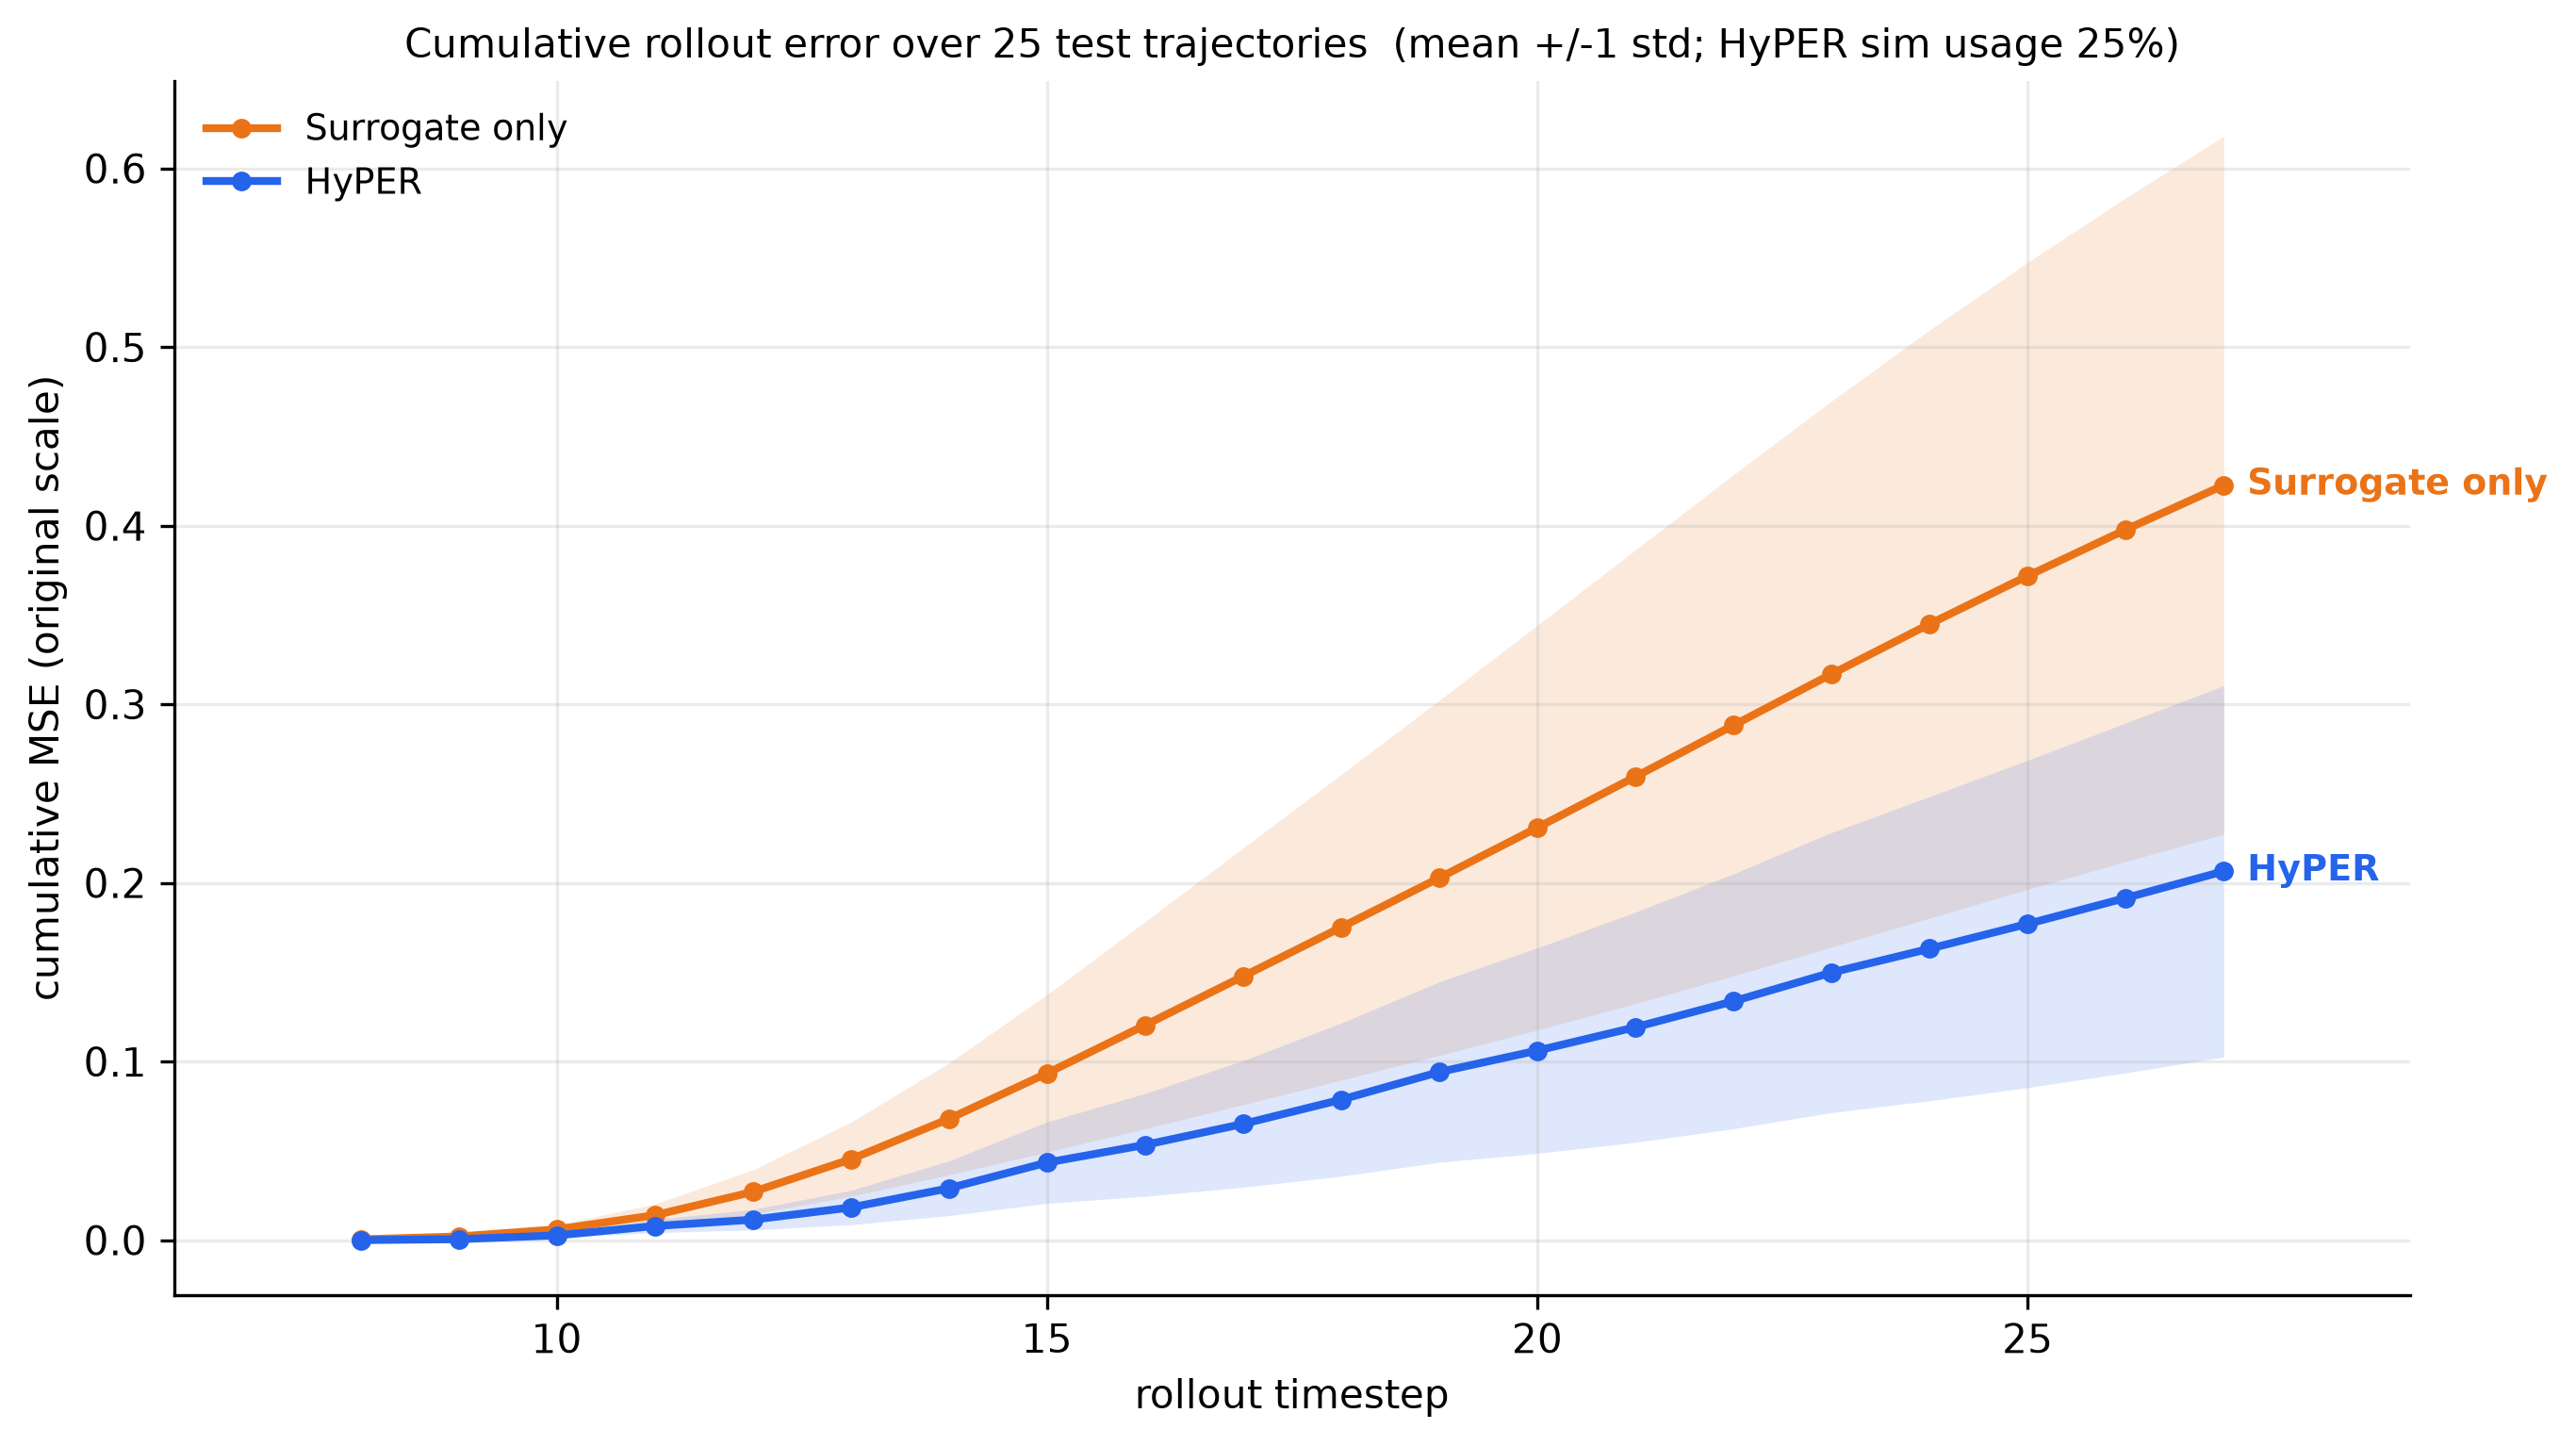

Final cumulative MSE (mean over 25 traj): HyPER 0.206 vs surrogate 0.423
HyPER reduces final cumulative rollout error by 51.1% on average.


In [8]:
# --- Aggregate: cumulative rollout error, HyPER vs surrogate-only (10 test trajectories) ---
# A single trajectory shows the idea; aggregating removes luck. For each of the first
# N test trajectories we run both rollouts and accumulate the per-step MSE into a
# CUMULATIVE error curve (running sum over the rollout) -- the quantity that makes
# error compounding visible. We plot the mean curve for each method with a +/-1 std
# band across trajectories. (A subset of the test set for speed; raise N for tighter bands.)
from itertools import islice
from tqdm.auto import tqdm

N_TRAJ = 25
T = FT - ST
steps = np.arange(ST, FT)

hyper_cum = np.zeros((N_TRAJ, T))   # cumulative MSE per trajectory, HyPER
surr_cum = np.zeros((N_TRAJ, T))    # cumulative MSE per trajectory, surrogate only
sim_usage = np.zeros(N_TRAJ)        # HyPER's simulator fraction per trajectory

for i, batch in enumerate(tqdm(islice(test_dataloader, N_TRAJ), total=N_TRAJ,
                               desc="Rollouts", unit="traj")):
    h = hyper_rollout(batch, actor, surrogate_400, greedy=True)
    s = hyper_rollout(batch, _ZeroActor(), surrogate_400, greedy=True)
    hyper_cum[i] = np.cumsum(h["mses"].numpy())
    surr_cum[i] = np.cumsum(s["mses"].numpy())
    sim_usage[i] = h["percent_sim"]

# Mean + spread across trajectories.
h_mean, h_std = hyper_cum.mean(0), hyper_cum.std(0)
s_mean, s_std = surr_cum.mean(0), surr_cum.std(0)
final_reduction = (1 - h_mean[-1] / s_mean[-1]) * 100

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
for mean, std, color, label in [(s_mean, s_std, C_SURR, "Surrogate only"),
                                (h_mean, h_std, C_HYPER, "HyPER")]:
    ax.fill_between(steps, mean - std, mean + std, color=color, alpha=0.15, linewidth=0)
    ax.plot(steps, mean, color=color, lw=2, marker="o", ms=4, label=label)
    # Direct label at the end of each line (identity not by color alone).
    ax.annotate(label, (steps[-1], mean[-1]), color=color, fontsize=9, fontweight="bold",
                va="center", xytext=(6, 0), textcoords="offset points")

ax.set_xlabel("rollout timestep")
ax.set_ylabel("cumulative MSE (original scale)")
ax.set_title(f"Cumulative rollout error over {N_TRAJ} test trajectories  "
             f"(mean +/-1 std; HyPER sim usage {sim_usage.mean()*100:.0f}%)", fontsize=10)
ax.legend(loc="upper left", frameon=False, fontsize=9)
ax.grid(True, alpha=0.25); ax.margins(x=0.10)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
plt.show()

print(f"Final cumulative MSE (mean over {N_TRAJ} traj): "
      f"HyPER {h_mean[-1]:.3f} vs surrogate {s_mean[-1]:.3f}")
print(f"HyPER reduces final cumulative rollout error by {final_reduction:.1f}% on average.")

In [9]:
# --- Animate one trajectory: ground truth, surrogate-only, HyPER, and their abs errors ---
# Reuses the single-trajectory rollouts from the figure above (hyper / surr_only on
# viz_batch, greedy). Five panels animate over the rollout: the three smoke fields share
# one sequential density colormap; the two |error| maps share a single-hue "Reds" ramp
# (lighter = lower error) with a common scale so HyPER vs surrogate is a fair comparison.
# Frames where HyPER invoked the simulator are flagged in the title.
from matplotlib import animation
from IPython.display import HTML

gts = hyper["gts"].numpy()                       # (T, H, W) ground truth
pred_surr = surr_only["preds"].numpy()           # surrogate-only prediction
pred_hyper = hyper["preds"].numpy()              # HyPER prediction
err_surr = np.abs(pred_surr - gts)               # |surrogate - truth|
err_hyper = np.abs(pred_hyper - gts)             # |HyPER - truth|
sim_steps = set(np.where(hyper["sim_mask"].numpy())[0].tolist())

vmin, vmax = float(gts.min()), float(gts.max())          # shared smoke-density scale
emax = float(max(err_surr.max(), err_hyper.max()))       # shared error scale

panels = [("Ground truth", gts, FIELD_CMAP, 0, vmin, vmax),
          ("Surrogate only", pred_surr, FIELD_CMAP, 0, vmin, vmax),
          ("HyPER", pred_hyper, FIELD_CMAP, 0, vmin, vmax),
          ("|error| surrogate", err_surr, "Reds", 1, 0.0, emax),
          ("|error| HyPER", err_hyper, "Reds", 1, 0.0, emax)]

fig, axes = plt.subplots(1, 5, figsize=(15, 3.6))
fig.set_dpi(90)  # keep the embedded jshtml video a reasonable size (cell 0 sets dpi=300 for stills)
ims = []
for ax, (title, data, cmap, group, lo, hi) in zip(axes, panels):
    im = ax.imshow(data[0], cmap=cmap, vmin=lo, vmax=hi, origin="lower")
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])
    ims.append(im)
# Grouped colorbars: one for the smoke fields, one for the error maps.
fig.colorbar(ims[0], ax=axes[:3], location="bottom", shrink=0.6, pad=0.04, label="smoke density")
fig.colorbar(ims[3], ax=axes[3:], location="bottom", shrink=0.6, pad=0.04, label="absolute error")
suptitle = fig.suptitle("", fontsize=12)


def _update(k):
    for im, (_, data, *_rest) in zip(ims, panels):
        im.set_data(data[k])
    tag = "  —  HyPER sim correction" if k in sim_steps else ""
    suptitle.set_text(f"rollout timestep  t = {ST + k}{tag}")
    return ims


ani = animation.FuncAnimation(fig, _update, frames=gts.shape[0], interval=450, blit=False)
plt.close(fig)  # suppress the static duplicate; show only the animation
HTML(ani.to_jshtml())